# 01 · A block ETH metric for the mixed-field Ising chain

**Model.** The mixed-field Ising model (MFIM) on an open chain of $L$ spins:

$$H(g, h) = \sum_{i=0}^{L-2} Z_iZ_{i+1} + g\sum_i X_i + h\sum_i Z_i + 0.25\,Z_0 - 0.25\,Z_{L-1}.$$

The two edge fields break the reflection symmetry. With $g, h \neq 0$ the model is non-integrable. The reference point is PRX, $(g, h) = (1.08, 0.30)$.

**Metric.** Let $\rho(j, l; n)$ be the reduced density matrix of the $l+1$ contiguous spins $j, \dots, j+l$ in the $n$-th energy eigenstate. If eigenstates thermalize (ETH), neighbouring eigenstates look alike locally. The metric

$$\Phi(l) = \underset{j,\,n}{\mathrm{mean}}\ \mathrm{Tr}\big[(\rho(j, l; n+1) - \rho(j, l; n))^2\big]$$

averages over all $L - l$ block positions $j$ and all consecutive pairs of eigenstates in the middle 50 % of the spectrum. Lower $\Phi$ means more thermal. For Hermitian $\Delta$, $\mathrm{Tr}[\Delta^2]$ is the squared Frobenius norm, so $\Phi \ge 0$.

This notebook builds $\Phi$ step by step at one point ($L = 10$, PRX), checks it against the single-site expectation-value metric from the Huse–Khemani project, and shows the $(g, h)$ landscapes of $\Phi(0)$ and $\Phi(1)$. Larger blocks and longer chains are in notebook 02.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import eigh

from spin_eth import (PRX_G, PRX_H, compute_block_metric, mfim_components, phi_block, reduced_dm_block,
                      reduced_dm_pair, single_site_eev_metric, single_site_tables, spectral_window)
from spin_eth.io import load_npz
from spin_eth.plotting import landscape_panels, plot_min_scaling
from spin_eth.scans import grid_minimum

RESULTS = Path("../results")

## 1. Eigenstates at the PRX point (L = 10)

Full diagonalization, then keep the middle 50 % of the spectrum.

In [2]:
L, g0, h0 = 10, PRX_G, PRX_H
dim = 2**L
H_zz, H_x, H_z, H_edge = mfim_components(L)
energies, V = eigh(H_zz + g0 * H_x + h0 * H_z + H_edge)    # V[:, n] is eigenstate n

lo, hi = spectral_window(dim)
V_mid = V[:, lo:hi + 1]
n_mid = V_mid.shape[1]
print(f"L={L} (dim {dim}), g={g0}, h={h0}:  energies in [{energies[0]:.4f}, {energies[-1]:.4f}]")
print(f"Middle 50% window: eigenstates [{lo}, {hi + 1}), n_mid = {n_mid}")

L=10 (dim 1024), g=1.08, h=0.3:  energies in [-13.1998, 14.9887]
Middle 50% window: eigenstates [256, 768), n_mid = 512


## 2. Two-site reduced density matrices

For a pure state, the reduced density matrix of sites $(j, j+1)$ comes from reshaping $|n\rangle$ into a rank-$L$ tensor, moving sites $j, j+1$ to the front, flattening to a $4 \times 2^{L-2}$ matrix $\psi$, and forming $\psi\psi^\dagger$. The basis order is $|00\rangle, |01\rangle, |10\rangle, |11\rangle$, with the first bit on site $j$.

Eigenstate n=512, sites (4, 5):
  Tr rho = 1.00000000,  max|rho - rho^dag| = 0.0e+00
  eigenvalues: [0.20677123 0.2308291  0.23900766 0.32339201]
[[ 0.23242 -0.01568  0.01169  0.01176]
 [-0.01568  0.2531  -0.00225 -0.04439]
 [ 0.01169 -0.00225  0.23532  0.02614]
 [ 0.01176 -0.04439  0.02614  0.27916]]



All 9 pairs x 512 eigenstates: max |Tr rho - 1| = 4.6e-15


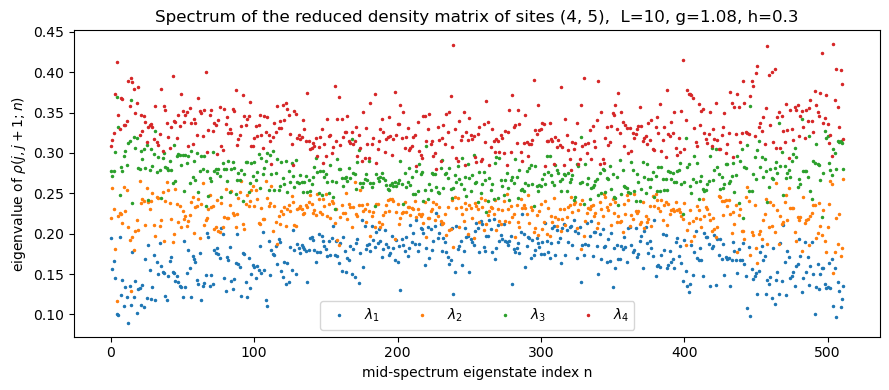

In [3]:
n_test, j_test = n_mid // 2, L // 2 - 1
rho_test = reduced_dm_pair(V_mid[:, n_test], j_test, L)
print(f"Eigenstate n={lo + n_test}, sites ({j_test}, {j_test + 1}):")
print(f"  Tr rho = {np.trace(rho_test).real:.8f},  max|rho - rho^dag| = {np.max(np.abs(rho_test - rho_test.conj().T)):.1e}")
print(f"  eigenvalues: {np.linalg.eigvalsh(rho_test)}")
print(np.array2string(rho_test.real, precision=5, suppress_small=True))

n_pairs = L - 1
rho_pairs = {j: np.stack([reduced_dm_pair(V_mid[:, n], j, L) for n in range(n_mid)]) for j in range(n_pairs)}
max_trace_err = max(np.max(np.abs(np.trace(r, axis1=1, axis2=2).real - 1)) for r in rho_pairs.values())
print(f"\nAll {n_pairs} pairs x {n_mid} eigenstates: max |Tr rho - 1| = {max_trace_err:.1e}")

evals_j = np.linalg.eigvalsh(rho_pairs[j_test])
fig, ax = plt.subplots(figsize=(9, 4))
for k in range(4):
    ax.plot(evals_j[:, k], ".", ms=3, label=f"$\\lambda_{k + 1}$")
ax.set_xlabel("mid-spectrum eigenstate index n")
ax.set_ylabel(r"eigenvalue of $\rho(j, j+1; n)$")
ax.set_title(f"Spectrum of the reduced density matrix of sites ({j_test}, {j_test + 1}),  L={L}, g={g0}, h={h0}")
ax.legend(ncol=4)
fig.tight_layout()
plt.show()

## 3. Φ(1) from consecutive eigenstates

9 site pairs x 511 consecutive eigenstate pairs = 4599 terms
Phi(1) = 1.927793e-02   (min 1.169346e-03, max 1.409222e-01, std 1.177775e-02)


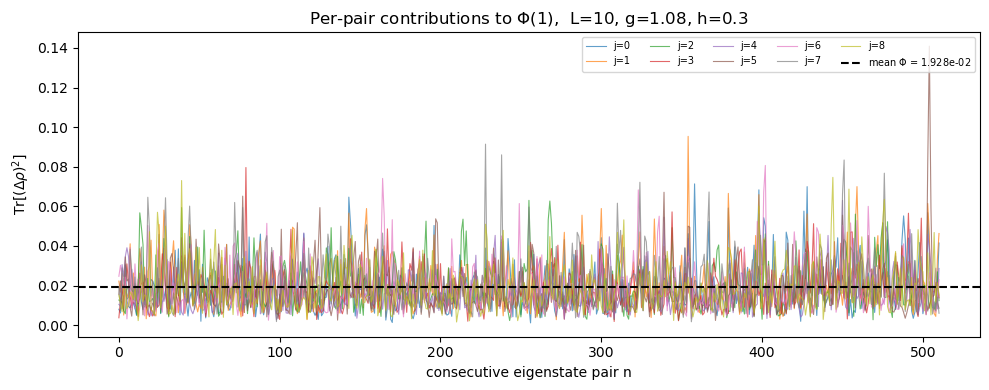

In [4]:
tr_delta_sq = np.array([np.einsum("nij,nji->n", d, d).real
                        for d in (np.diff(rho_pairs[j], axis=0) for j in range(n_pairs))])   # (pairs, n_mid-1)
Phi1 = float(np.mean(tr_delta_sq))
print(f"{n_pairs} site pairs x {n_mid - 1} consecutive eigenstate pairs = {tr_delta_sq.size} terms")
print(f"Phi(1) = {Phi1:.6e}   (min {tr_delta_sq.min():.6e}, max {tr_delta_sq.max():.6e}, std {tr_delta_sq.std():.6e})")

fig, ax = plt.subplots(figsize=(10, 4))
for j in range(n_pairs):
    ax.plot(tr_delta_sq[j], lw=0.8, alpha=0.7, label=f"j={j}")
ax.axhline(Phi1, color="k", lw=1.5, ls="--", label=f"mean $\\Phi$ = {Phi1:.3e}")
ax.set_xlabel("consecutive eigenstate pair n")
ax.set_ylabel(r"$\mathrm{Tr}[(\Delta\rho)^2]$")
ax.set_title(f"Per-pair contributions to $\\Phi(1)$,  L={L}, g={g0}, h={h0}")
ax.legend(fontsize=7, ncol=5, loc="upper right")
fig.tight_layout()
plt.show()

## 4. Larger blocks: Φ(l)

The same construction for $l + 1$ spins gives $2^{l+1}$-dimensional reduced density matrices at $L - l$ positions. `compute_block_metric` builds every $\rho(j, l; n)$ explicitly. The vectorized `phi_block`, used everywhere else, must agree with it.

Single state (n=512, j=4, l=2): shape (8, 8), Tr = 1.0000000000, max|Im| = 0.0e+00 (real H -> real rho), min eigenvalue = 6.43e-02


l=1: block of 2 spins, 4x4 matrices, 9 positions:  Phi = 1.927793e-02   (phi_block: 1.927793e-02)


l=2: block of 3 spins, 8x8 matrices, 8 positions:  Phi = 3.257515e-02   (phi_block: 3.257515e-02)


l=3: block of 4 spins, 16x16 matrices, 7 positions:  Phi = 5.189306e-02   (phi_block: 5.189306e-02)


l=4: block of 5 spins, 32x32 matrices, 6 positions:  Phi = 8.593745e-02   (phi_block: 8.593745e-02)


l=5: block of 6 spins, 64x64 matrices, 5 positions:  Phi = 1.498490e-01   (phi_block: 1.498490e-01)

Cross-check l=1: section 3 gives 1.927793e-02, compute_block_metric gives 1.927793e-02

   l   max|Tr-1|    max|Im|  max|rho-rho^dag|  min eigenvalue
   1    4.55e-15   0.00e+00          0.00e+00        7.23e-02
   2    4.44e-15   0.00e+00          0.00e+00        9.16e-03
   3    4.44e-15   0.00e+00          0.00e+00        7.23e-05


   4    4.44e-15   0.00e+00          0.00e+00        5.77e-16


   5    4.44e-15   0.00e+00          0.00e+00       -1.18e-16


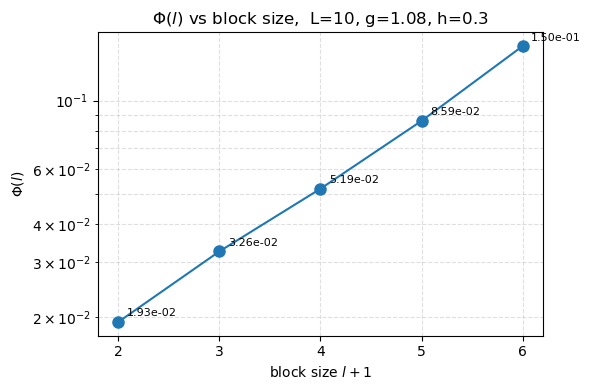

In [5]:
l_demo, j_demo = 2, L // 2 - 1
rho_demo = reduced_dm_block(V_mid[:, n_mid // 2], j_demo, l_demo, L)
print(f"Single state (n={lo + n_mid // 2}, j={j_demo}, l={l_demo}): shape {rho_demo.shape}, Tr = {np.trace(rho_demo).real:.10f}, "
      f"max|Im| = {np.max(np.abs(rho_demo.imag)):.1e} (real H -> real rho), min eigenvalue = {np.linalg.eigvalsh(rho_demo).min():.2e}")

l_values = list(range(1, min(6, L - 1)))
Phi_l, rho_blocks = {}, {}
for l in l_values:
    rho_blocks[l], _, Phi_l[l] = compute_block_metric(V_mid, L, l)
    print(f"l={l}: block of {l + 1} spins, {2**(l + 1)}x{2**(l + 1)} matrices, {L - l} positions:  "
          f"Phi = {Phi_l[l]:.6e}   (phi_block: {phi_block(V_mid, L, l):.6e})")
print(f"\nCross-check l=1: section 3 gives {Phi1:.6e}, compute_block_metric gives {Phi_l[1]:.6e}")

print(f"\n  {'l':>2}  {'max|Tr-1|':>10}  {'max|Im|':>9}  {'max|rho-rho^dag|':>16}  {'min eigenvalue':>14}")
for l in l_values:
    all_rho = np.concatenate([rho_blocks[l][j] for j in range(L - l)])
    print(f"  {l:>2}  {np.max(np.abs(np.trace(all_rho, axis1=1, axis2=2).real - 1)):10.2e}  "
          f"{np.max(np.abs(all_rho.imag)):9.2e}  {np.max(np.abs(all_rho - all_rho.conj().swapaxes(1, 2))):16.2e}  "
          f"{np.linalg.eigvalsh(all_rho).min():14.2e}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(np.array(l_values) + 1, [Phi_l[l] for l in l_values], "o-", ms=8)
for l in l_values:
    ax.annotate(f"{Phi_l[l]:.2e}", (l + 1, Phi_l[l]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("block size $l+1$")
ax.set_ylabel(r"$\Phi(l)$")
ax.set_title(f"$\\Phi(l)$ vs block size,  L={L}, g={g0}, h={h0}")
ax.set_xticks(np.array(l_values) + 1)
ax.grid(True, which="both", ls="--", alpha=0.4)
fig.tight_layout()
plt.show()

## 5. Φ(0) and the single-site metric

For a real Hamiltonian the eigenstates are real, and the single-site reduced density matrix is

$$\rho_j = \tfrac12\begin{pmatrix}1 + \langle Z_j\rangle & \langle X_j\rangle \\ \langle X_j\rangle & 1 - \langle Z_j\rangle\end{pmatrix}
\quad\Rightarrow\quad \mathrm{Tr}[(\Delta\rho_j)^2] = \tfrac12\big[(\Delta\langle Z_j\rangle)^2 + (\Delta\langle X_j\rangle)^2\big].$$

So $\Phi(0)$ is exactly half the all-site squared expectation-value metric of the Huse–Khemani project, and the two landscapes share their minima. The $l = 0$ scans use this cheaper form.

In [6]:
phi0_explicit = compute_block_metric(V_mid, L, 0)[2]
sz_diag, sx_perm = single_site_tables(L)
phi0_eev = single_site_eev_metric(V_mid, sz_diag, sx_perm) / 2
print(f"Phi(0) from reduced density matrices: {phi0_explicit:.8e}")
print(f"(1/2) x single-site EEV metric:       {phi0_eev:.8e}")
print(f"match: {np.isclose(phi0_explicit, phi0_eev)}")

Phi(0) from reduced density matrices: 8.59473609e-03
(1/2) x single-site EEV metric:       8.59473609e-03
match: True


## 6. Φ(0) and Φ(1) landscapes, L = 9–11

The grid is $g \in [1, 2]$ (21 points) by $h \in [0.2, 0.8]$ (13 points). The landscapes are precomputed by `scripts/compute_landscapes.py` and stored in `results/landscapes/`. Red circle: PRX. Cyan square: Kim & Huse (2013). Yellow star: grid minimum.

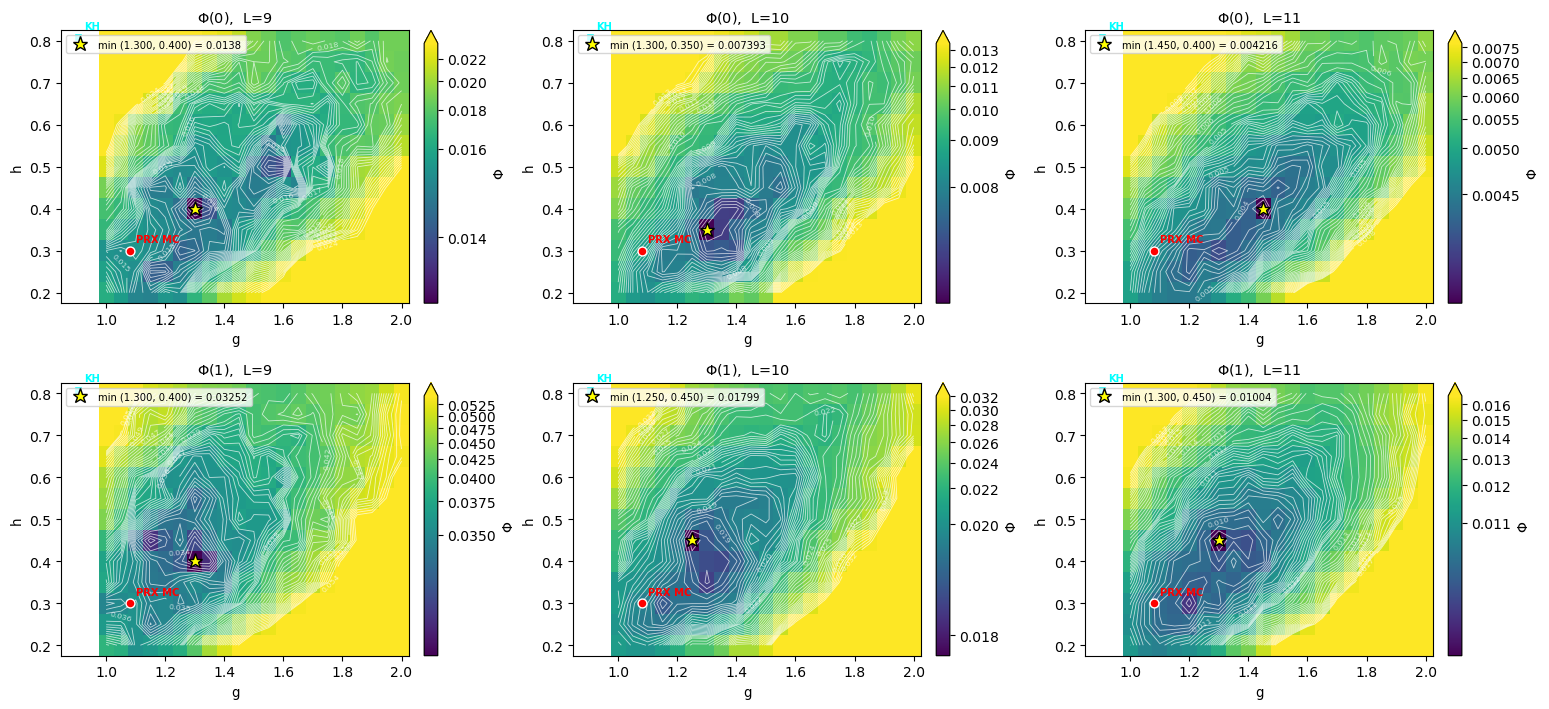

 l    L   min Phi(l)      g*      h*  |g*-1.08|  |h*-0.30|
 0    9   1.3805e-02   1.300   0.400     0.2200     0.1000
 0   10   7.3933e-03   1.300   0.350     0.2200     0.0500
 0   11   4.2159e-03   1.450   0.400     0.3700     0.1000
 1    9   3.2525e-02   1.300   0.400     0.2200     0.1000
 1   10   1.7990e-02   1.250   0.450     0.1700     0.1500
 1   11   1.0035e-02   1.300   0.450     0.2200     0.1500
L=9: Phi(1) minimum coincides with the Phi(0) minimum
L=10: Phi(1) minimum differs from the Phi(0) minimum
L=11: Phi(1) minimum differs from the Phi(0) minimum


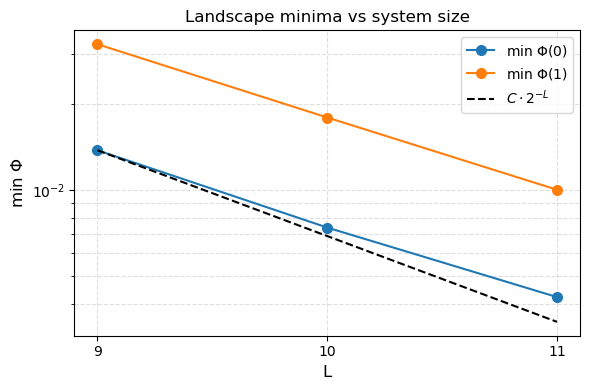

In [7]:
L_values = [9, 10, 11]
land = {L_: load_npz(RESULTS / "landscapes" / f"mfim_L{L_}.npz") for L_ in L_values}
key = {l: f"l{l}_posall_frac0.5" for l in (0, 1)}

landscape_panels([(land[L_][key[l]], land[L_]["g"], land[L_]["h"], f"$\\Phi({l})$,  L={L_}")
                  for l in (0, 1) for L_ in L_values], ncols=3);

minima = {(l, L_): grid_minimum(land[L_][key[l]], land[L_]["g"], land[L_]["h"]) for l in (0, 1) for L_ in L_values}
print(f"{'l':>2}  {'L':>3}  {'min Phi(l)':>11}  {'g*':>6}  {'h*':>6}  {'|g*-1.08|':>9}  {'|h*-0.30|':>9}")
for (l, L_), (v, g, h) in minima.items():
    print(f"{l:>2}  {L_:>3}  {v:11.4e}  {g:6.3f}  {h:6.3f}  {abs(g - PRX_G):9.4f}  {abs(h - PRX_H):9.4f}")
for L_ in L_values:
    same = minima[(0, L_)][1:] == minima[(1, L_)][1:]
    print(f"L={L_}: Phi(1) minimum {'coincides with' if same else 'differs from'} the Phi(0) minimum")

plot_min_scaling(L_values, {f"min $\\Phi({l})$": [minima[(l, L_)][0] for L_ in L_values] for l in (0, 1)},
                 title="Landscape minima vs system size", ylabel=r"min $\Phi$");